In [3]:
#importacion de librerias a utilizar
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.style as style


In [4]:
#Lectura del data set
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/tips.csv"
df_tips = pd.read_csv(url)

In [6]:
# Verificar tipos de datos
print(df_tips.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   total_bill  244 non-null    float64
 1   tip         244 non-null    float64
 2   sex         244 non-null    object 
 3   smoker      244 non-null    object 
 4   day         244 non-null    object 
 5   time        244 non-null    object 
 6   size        244 non-null    int64  
dtypes: float64(2), int64(1), object(4)
memory usage: 13.5+ KB
None


In [7]:
#las 5 primeras filas
print(df_tips.head())

   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4


In [11]:
#las 5 ultimas filas
df_tips.tail()

,total_bill,tip,sex,smoker,day,time,size
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2
243,18.78,3.00,Female,No,Thur,Dinner,2


In [10]:
#Nombre de los atributos
df_tips.columns

Index(['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size'], dtype='object')

In [13]:
#Dimension del dataset
print(df_tips.shape)

(244, 7)


In [14]:
#Tipo de dato para cada columna
df_tips.dtypes

,0
total_bill,float64
tip,float64
sex,object
smoker,object
day,object
time,object
size,int64


In [18]:
type(df_tips)

pandas.core.frame.DataFrame

### Descripción de DataFrame de pandas

**Datos tabulares bidimensionales, de tamaño mutable y potencialmente heterogéneos.**

Esta estructura de datos también contiene ejes etiquetados (filas y columnas). Las operaciones aritméticas se alinean tanto en las etiquetas de fila como de columna. Puede considerarse como un contenedor similar a un diccionario para objetos de tipo `Series`. Es la estructura de datos principal de pandas.

#### Parámetros
----------
* **data** : *ndarray (estructurado u homogéneo), Iterable, dict, o DataFrame*
  El diccionario puede contener Series, arreglos, constantes, dataclasses u objetos similares a listas. Si los datos son un diccionario, el orden de las columnas sigue el orden de inserción. Si un diccionario contiene Series que tienen un índice definido, se alineará por su índice. Esta alineación también ocurre si los datos son una Serie o un DataFrame en sí mismos. La alineación se realiza sobre las entradas de tipo Series/DataFrame.
  Si los datos son una lista de diccionarios, el orden de las columnas sigue el orden de inserción.

* **index** : *Index o tipo arreglo (array-like)*
  Índice a utilizar para el marco de datos resultante. Por defecto será un `RangeIndex` si no se incluye información de indexación en los datos de entrada y no se proporciona ningún índice.

* **columns** : *Index o tipo arreglo (array-like)*
  Etiquetas de columna a utilizar para el marco de datos resultante cuando los datos de entrada no las tienen, por defecto `RangeIndex(0, 1, 2, ..., n)`. Si los datos ya contienen etiquetas de columna, se realizará una selección de columnas en su lugar.

* **dtype** : *dtype, por defecto None*
  Tipo de dato a forzar. Solo se permite un único tipo de dato. Si es `None`, se infiere.

* **copy** : *bool o None, por defecto None*
  Copia los datos de las entradas. Para datos de tipo diccionario, el comportamiento por defecto (`None`) actúa como `copy=True`. Para una entrada de tipo DataFrame o ndarray bidimensional, el comportamiento por defecto de `None` actúa como `copy=False`.
  Si los datos son un diccionario que contiene una o más Series (posiblemente de diferentes tipos de datos), `copy=False` asegurará que estas entradas no se copien.

#### Véase también
--------
* **DataFrame.from_records** : Constructor a partir de tuplas, también arreglos de registros.
* **DataFrame.from_dict** : A partir de diccionarios de Series, arreglos o diccionarios.
* **read_csv** : Lee un archivo de valores separados por comas (CSV) en un DataFrame.
* **read_table** : Lee un archivo delimitado general en un DataFrame.
* **read_clipboard** : Lee texto desde el portapapeles en un DataFrame.

In [20]:
# Verificar valores faltantes y filas duplicadas
print("Valores nulos por columna:\n", df_tips.isnull().sum())
print("Cantidad de filas duplicadas:", df_tips.duplicated().sum())


Valores nulos por columna:
 total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64
Cantidad de filas duplicadas: 1


In [21]:
# Estadísticos descriptivos de variables numéricas
numeric_cols = ["total_bill", "tip", "size"]
display(df_tips[numeric_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
total_bill,244.0,19.785943,8.902412,3.07,13.3475,17.795,24.1275,50.81
tip,244.0,2.998279,1.383638,1.00,2.0000,2.900,3.5625,10.00
size,244.0,2.569672,0.951100,1.00,2.0000,2.000,3.0000,6.00


Análisis de distribución: Gráfico de barras (Variables categóricas)

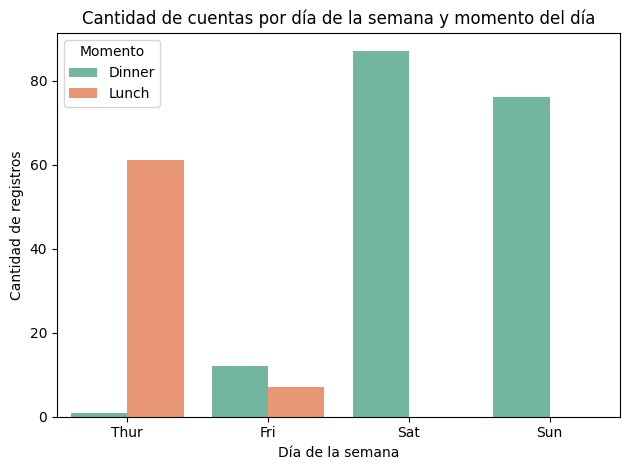

In [23]:
# Gráfico de barras de frecuencia por día de la semana, segmentado por momento del día
fig, ax = plt.subplots()
sns.countplot(
    data=df_tips,
    x="day",
    hue="time",
    order=["Thur", "Fri", "Sat", "Sun"],
    palette="Set2",
    ax=ax,
)
ax.set_title("Cantidad de cuentas por día de la semana y momento del día")
ax.set_xlabel("Día de la semana")
ax.set_ylabel("Cantidad de registros")
ax.legend(title="Momento")
plt.tight_layout()
plt.show()

Asimetría (Skewness) y Curtosis (Variables numéricas)

In [25]:
from scipy.stats import skew, kurtosis

for col in ["total_bill", "tip"]:
  col_skew = skew(df_tips[col], bias=False)
  col_kurt = kurtosis(
      df_tips[col], bias=False
  )  # Exceso de curtosis (Fisher: normal = 0)
  mean_val = df_tips[col].mean()
  median_val = df_tips[col].median()

  forma_asimetria = (
      "asimetría positiva (cola a la derecha)"
      if col_skew > 0
      else "asimetría negativa (cola a la izquierda)"
  )
  print(f"--- Variable: {col} ---")
  print(f"Media: {mean_val:.2f} | Mediana: {median_val:.2f}")
  print(f"Skewness: {col_skew:.4f} -> {forma_asimetria}")
  print(f"Curtosis (exceso): {col_kurt:.4f}\n")

--- Variable: total_bill ---
Media: 19.79 | Mediana: 17.80
Skewness: 1.1332 -> asimetría positiva (cola a la derecha)
Curtosis (exceso): 1.2185

--- Variable: tip ---
Media: 3.00 | Mediana: 2.90
Skewness: 1.4655 -> asimetría positiva (cola a la derecha)
Curtosis (exceso): 3.6484



Estos resultados nos ayudan a entender cómo se distribuyen y se comportan los datos de las cuentas (total_bill) y las propinas (tip):

1. Variable: total_bill (Cuenta total)

Media (19.79) y Mediana (17.80): Al ser
la media mayor que la mediana, se confirma visual y matemáticamente que la distribución está sesgada.

Skewness (Asimetría) = 1.1332 (Asimetría positiva): Esto significa que la gran mayoría de los clientes del restaurante pagan cuentas relativamente bajas o moderadas (concentradas a la izquierda, cerca del valor de la mediana de $17.80), pero hay una minoría de clientes que realizan consumos excepcionalmente altos, lo que estira la curva hacia la derecha (creando una "cola" larga a la derecha).

Curtosis (exceso) = 1.2185: Al ser un valor mayor que 0, indica una distribución leptocúrtica. Los datos están ligeramente más concentrados alrededor de la media y tienen colas un poco más pesadas que una distribución normal teórica (es decir, hay una probabilidad de valores extremos más alta de lo habitual).

2. Variable: tip (Propina)

Media (3.00) y Mediana (2.90): Al igual que la cuenta, la media es superior a la mediana, mostrando una tendencia a que unos pocos valores altos eleven el promedio global de propinas.

Skewness (Asimetría) = 1.4655 (Asimetría positiva): El sesgo positivo es aún más pronunciado aquí. La mayoría de las propinas se agrupan en valores pequeños (alrededor de $2 o $$2 o $3), pero existen clientes muy generosos que dejan propinas atípicamente altas (por ejemplo, $5, $$5, $10 o más), extendiendo la cola derecha de la gráfica.

Curtosis (exceso) = 3.6484: Este es un valor notablemente alto (muy superior a 0). Indica una forma fuertemente leptocúrtica. Esto significa que la distribución de las propinas es muy empinada o "puntiaguda" alrededor de los valores más comunes, con colas sumamente gruesas. En la práctica, te dice que casi todo el mundo deja un estándar de propina muy similar, pero cuando hay excepciones (valores atípicos), estas pueden ser sumamente extremas.


Detección visual de outliers: Boxplot y Violin Plot

/tmp/ipykernel_858/2147725792.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


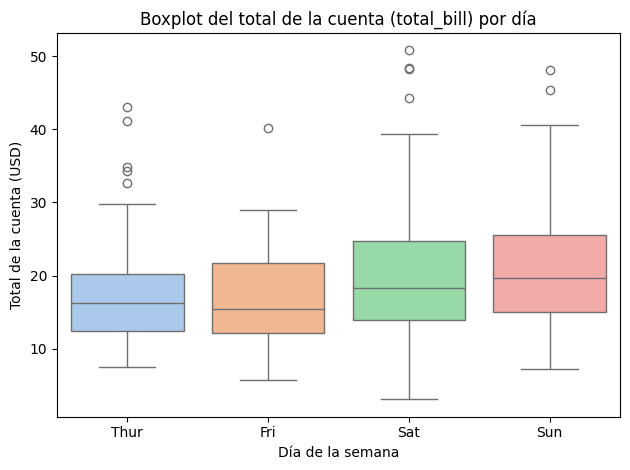

In [27]:
# Boxplot de 'total_bill' por día de la semana
fig, ax = plt.subplots()
sns.boxplot(
    data=df_tips,
    x="day",
    y="total_bill",
    order=["Thur", "Fri", "Sat", "Sun"],
    palette="pastel",
    ax=ax,
)
ax.set_title("Boxplot del total de la cuenta (total_bill) por día")
ax.set_xlabel("Día de la semana")
ax.set_ylabel("Total de la cuenta (USD)")
plt.tight_layout()
plt.show()

**Conclusion de analisis del El gráfico de cajas (Boxplot) del total de la cuenta por día **

Expresa cómo se distribuyen los consumos de los clientes según el día de la semana. Aquí te explico paso a paso cómo interpretar lo que estás viendo:

1. La Línea Central (La Mediana)
La línea horizontal que divide cada caja representa la mediana (el valor central de los datos).
Notamos que la mediana de la cuenta es más baja los jueves y viernes (alrededor de $15 - $$15 - $16) y sube notablemente los sábados y domingos (cercana a los $18 - $$18 - $20). Esto sugiere que la gente tiende a gastar más en cuentas individuales durante el fin de semana.

2. La Caja (Rango Intercuartílico - IQR)
El cuerpo de la caja representa el 50% central de los datos (desde el percentil 25 al 75).
La caja del sábado es la más alta (más larga verticalmente), lo que significa que el comportamiento de gasto de los clientes es más variable ese día. Algunos gastan poco y otros mucho.
Los jueves la caja es más compacta, lo que indica que el gasto de los clientes ese día es más homogéneo o predecible.

3. Los Bigotes (Líneas verticales)
Las líneas que sobresalen hacia arriba y abajo de las cajas muestran el rango de la gran mayoría de los datos (excluyendo valores extremos).
Los límites inferiores de los bigotes son similares todos los días (siempre hay personas que consumen montos mínimos de alrededor de $3 a $$3 a $7).
Los límites superiores muestran que los fines de semana (sábado y domingo) el rango general de cuentas normales se extiende a montos más altos (hasta casi $40) en comparación con los días de semana.

4. Los Puntos Individuales (Valores Atípicos / Outliers)
Los círculos pequeños que quedan por encima del bigote superior representan clientes que gastaron mucho más de lo habitual para ese día específico.
El jueves presenta varios valores atípicos (cuentas de más de $32). * El **sábado** registra el consumo más alto de todo el conjunto de datos, con una cuenta individual que supera los **$$32). * El **sábado** registra el consumo más alto de todo el conjunto de datos, con una cuenta individual que supera los **$50**.

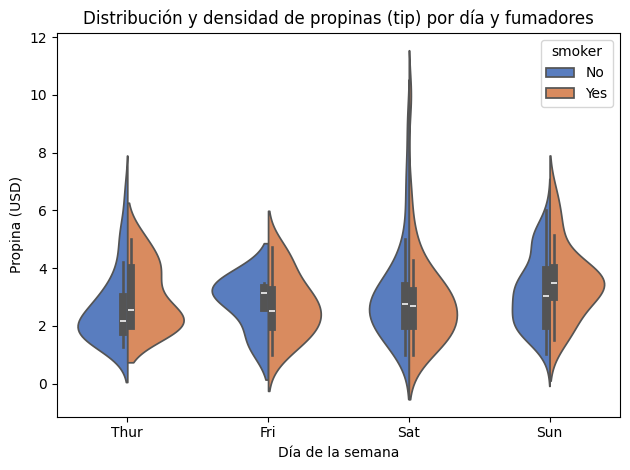

In [28]:
# Violin Plot de 'tip' según condición de fumador
fig, ax = plt.subplots()
sns.violinplot(
    data=df_tips,
    x="day",
    y="tip",
    hue="smoker",
    split=True,
    order=["Thur", "Fri", "Sat", "Sun"],
    palette="muted",
    ax=ax,
)
ax.set_title("Distribución y densidad de propinas (tip) por día y fumadores")
ax.set_xlabel("Día de la semana")
ax.set_ylabel("Propina (USD)")
plt.tight_layout()
plt.show()

**Conclusiones El gráfico de violín (Violin Plot) **

Analiza la distribución y densidad de las propinas (tip) recibidas cada día de la semana, comparando además el comportamiento entre fumadores (Yes en naranja) y no fumadores (No en azul) mediante una división interna (parámetro split=True).


Aquí tienes la explicación detallada de lo que expresa el gráfico:

1. ¿Qué es cada "violín"?
Cada mitad de un violín representa la distribución de probabilidad (densidad) de las propinas para ese grupo.
La parte más ancha del violín indica los valores de propina más comunes o frecuentes.
El extremo más alto o delgado muestra el rango de propinas más altas pero menos frecuentes.

2. El interior del violín (Mini Boxplot)
La línea blanca central o el pequeño bloque interno representa la mediana y el rango intercuartílico.
Verás que en la mayoría de los días, las medianas (el centro del violín) están muy alineadas alrededor de los $2 a $$2 a $3 USD.

3. Comparación por Día y Condición de Fumador:

Jueves (Thur): Las distribuciones son bastante similares. Tanto fumadores como no fumadores tienden a dejar propinas muy concentradas alrededor de los $2 USD, aunque los no fumadores (azul) presentan una cola ligeramente más alta que alcanza casi los $$2 USD, aunque los no fumadores (azul) presentan una cola ligeramente más alta que alcanza casi los $8 USD.

Viernes (Fri): Es el día con menor variabilidad y violines más cortos. Las propinas de los no fumadores están sumamente concentradas alrededor de los $3 USD, mientras que los fumadores muestran una distribución un poco más dispersa hacia abajo. *

Sábado (Sat):** ¡Es el día con los datos más extremos! El violín de los **no fumadores (azul)** se estira muchísimo hacia arriba, mostrando una cola muy larga que alcanza el máximo histórico de propina del dataset (cerca de los **$$3 USD, mientras que los fumadores muestran una distribución un poco más dispersa hacia abajo. Los fumadores también muestran propinas altas, pero con una densidad más acumulada en valores moderados.

Domingo (Sun): Las distribuciones son bastante redondeadas en la base, lo que significa que el promedio de propina se mantiene firme en los $3 USD para ambos grupos, con los no fumadores mostrando un comportamiento levemente más estirado hacia propinas de $$3 USD para ambos grupos, con los no fumadores mostrando un comportamiento levemente más estirado hacia propinas de $6 a $8 USD.

**Segmentación de outliers con el método IQR**

---



In [31]:
def detectar_outliers_iqr(df: pd.DataFrame, columna: str):
  q1 = df[columna].quantile(0.25)
  q3 = df[columna].quantile(0.75)
  iqr = q3 - q1

  limite_inferior = q1 - 1.5 * iqr
  limite_superior = q3 + 1.5 * iqr

  outliers = df[
      (df[columna] < limite_inferior) | (df[columna] > limite_superior)
  ].copy()
  outliers["tipo_outlier"] = np.where(
      outliers[columna] > limite_superior, "Superior", "Inferior"
  )

  return {
      "q1": q1,
      "q3": q3,
      "iqr": iqr,
      "limite_inferior": limite_inferior,
      "limite_superior": limite_superior,
      "outliers_df": outliers,
  }


for col in ["total_bill", "tip"]:
  res = detectar_outliers_iqr(df_tips, col)
  n_out = len(res["outliers_df"])
  pct_out = (n_out / len(df_tips)) * 100
  print(f"=== Outliers IQR en '{col}' ===")
  print(
      f"Q1: {res['q1']:.2f} | Q3: {res['q3']:.2f} | IQR: {res['iqr']:.2f}"
  )
  print(
      f"Límites: [{res['limite_inferior']:.2f}, {res['limite_superior']:.2f}]"
  )
  print(f"Outliers detectados: {n_out} registros ({pct_out:.2f}%)\n")
  display(res["outliers_df"].sort_values(by=col, ascending=False))

=== Outliers IQR en 'total_bill' ===
Q1: 13.35 | Q3: 24.13 | IQR: 10.78
Límites: [-2.82, 40.30]
Outliers detectados: 9 registros (3.69%)



,total_bill,tip,sex,smoker,day,time,size,tipo_outlier
170,50.81,10.00,Male,Yes,Sat,Dinner,3,Superior
212,48.33,9.00,Male,No,Sat,Dinner,4,Superior
59,48.27,6.73,Male,No,Sat,Dinner,4,Superior
156,48.17,5.00,Male,No,Sun,Dinner,6,Superior
182,45.35,3.50,Male,Yes,Sun,Dinner,3,Superior
102,44.30,2.50,Female,Yes,Sat,Dinner,3,Superior
197,43.11,5.00,Female,Yes,Thur,Lunch,4,Superior
142,41.19,5.00,Male,No,Thur,Lunch,5,Superior
184,40.55,3.00,Male,Yes,Sun,Dinner,2,Superior


=== Outliers IQR en 'tip' ===
Q1: 2.00 | Q3: 3.56 | IQR: 1.56
Límites: [-0.34, 5.91]
Outliers detectados: 9 registros (3.69%)



,total_bill,tip,sex,smoker,day,time,size,tipo_outlier
170,50.81,10.00,Male,Yes,Sat,Dinner,3,Superior
212,48.33,9.00,Male,No,Sat,Dinner,4,Superior
23,39.42,7.58,Male,No,Sat,Dinner,4,Superior
59,48.27,6.73,Male,No,Sat,Dinner,4,Superior
141,34.30,6.70,Male,No,Thur,Lunch,6,Superior
214,28.17,6.50,Female,Yes,Sat,Dinner,3,Superior
183,23.17,6.50,Male,Yes,Sun,Dinner,4,Superior
47,32.40,6.00,Male,No,Sun,Dinner,4,Superior
239,29.03,5.92,Male,No,Sat,Dinner,3,Superior


Conclusiones clave tras analizar los resultados de la detección de valores atípicos (outliers) con el método IQR:

1. Consistencia en la proporción de datos atípicos
Curiosamente, ambas variables (total_bill y tip) contienen exactamente la misma cantidad de outliers: 9 registros (3.69% del dataset total). Este porcentaje es bajo y completamente normal en conjuntos de datos reales, lo que demuestra que la gran mayoría de los datos se comportan de forma consistente.

2. Comportamiento en la Cuenta Total (total_bill)
Límites normales: El rango esperado para las cuentas normales según el IQR se sitúa entre $0.00 y $$0.00 y $40.30 (matemáticamente el límite inferior es $-2.82, pero físicamente la cuenta mínima es $$-2.82, pero físicamente la cuenta mínima es $0).
Outliers detectados: Hay 9 cuentas que superaron los **$40.30**. Esto nos indica que, aunque la gran mayoría de los clientes gastan montos estándar, existe un grupo selecto de mesas que generan un consumo muy elevado (llegando hasta un máximo de más de $$40.30**. Esto nos indica que, aunque la gran mayoría de los clientes gastan montos estándar, existe un grupo selecto de mesas que generan un consumo muy elevado (llegando hasta un máximo de más de $50). Estos casos excepcionales suelen estar asociados a grupos grandes o celebraciones especiales.

3. Comportamiento en las Propinas (tip)
Límites normales: Las propinas normales se sitúan en el rango de $0.00 a $$0.00 a $5.91 (el límite inferior matemático es $-0.34). * **Outliers detectados:** Hay 9 propinas que superan los **$$-0.34). * **Outliers detectados:** Hay 9 propinas que superan los **$5.91** (alcanzando propinas notables de hasta $10.00).
Relación de generosidad: Estos outliers representan a clientes sumamente generosos que deciden dar propinas fuera del estándar habitual de recompensa por el servicio.

4. Conclusión general para el negocio
Dado que los límites calculados no muestran valores atípicos negativos (no hay valores por debajo del límite inferior), todos los outliers en este restaurante son "atípicos positivos". Esto significa que los datos inusuales representan excelentes noticias para el negocio: clientes que consumen mucho y que recompensan al personal con propinas excepcionales.

```markdown
# Conclusiones Generales del Análisis del Dataset 'tips'

Tras realizar un Análisis Exploratorio de Datos (EDA) cuantitativo y cualitativo sobre el comportamiento de consumos y propinas en el restaurante, se presentan las siguientes conclusiones clave:

### 1. Perfil General de Consumo y Clientela
* **Distribución de Visitas:** El restaurante experimenta su mayor volumen de transacciones durante los fines de semana (especialmente el sábado, seguido por el domingo). Los días jueves y viernes registran una actividad significativamente menor.
* **Dinámica del Servicio (Almuerzo vs. Cena):** El servicio de cena (*Dinner*) predomina de forma absoluta los viernes, sábados y domingos. El almuerzo (*Lunch*) es el motor principal del día jueves, mientras que los fines de semana el servicio de almuerzo es prácticamente inexistente en este dataset.

### 2. Comportamiento del Gasto y Sesgo de las Variables
* **Cuentas más Altas el Fin de Semana:** La mediana del total de la cuenta aumenta notablemente de ~\$15 USD (jueves/viernes) a ~\$18-\$20 USD (sábado/domingo), lo que indica un cambio en el perfil de gasto del cliente durante los días no laborables.
* **Asimetría Positiva (Sesgo a la Derecha):** Ambas variables numéricas principales (`total_bill` con skewness de **1.13** y `tip` con skewness de **1.46**) muestran que la gran mayoría de las transacciones se concentran en montos bajos a moderados (mediana de cuenta de \$17.80 y propina de \$2.90), pero están fuertemente influenciadas por un grupo selecto de clientes que consumen y aportan valores muy por encima de la media.
* **Distribución Leptocúrtica en Propinas:** La variable `tip` presenta un exceso de curtosis muy alto (**3.65**). Esto indica que la inmensa mayoría de las propinas están estrictamente estandarizadas (alrededor de los \$2 - \$3 USD), pero la presencia de colas pesadas demuestra que, bajo condiciones excepcionales, las propinas atípicas pueden llegar a ser sumamente altas (hasta \$10 USD).

### 3. Impacto de los Hábitos (Fumadores vs. No Fumadores)
* El análisis a través del **Gráfico de Violín** revela que la condición de fumador o no fumador interactúa de forma interesante con el día de la semana. Los sábados, los clientes **no fumadores** presentan una dispersión de propinas mucho más extendida hacia valores altos en comparación con los fumadores, registrando el máximo absoluto del dataset.

### 4. Naturaleza y Decisión sobre los Valores Atípicos (Outliers)
* Mediante el método de Rango Intercuartílico (IQR), se identificaron exactamente **9 outliers (3.69%)** tanto para `total_bill` (cuentas mayores a \$40.30 USD) como para `tip` (propinas mayores a \$5.91 USD).
* **Decisión Metodológica:** Se determinó **mantener estos registros** en el dataset para análisis futuros y modelado, debido a que representan comportamiento comercial legítimo (mesas grandes, eventos especiales, clientes premium) y no errores de captura de datos. Eliminar estos registros subestimaría sistemáticamente el potencial de ingresos del restaurante.
```